# Measuring overlap through event concurrency

The first quantity records whether event $i$ uses the return at time $t,$ and the second counts all active events:

$$
I_{ti}=mathbf 1\{s_i\leq t\leq e_i\},\qquad
c_t=\sum_{i=1}^{n} I_{ti}.
$$

Here, $i\in\{1,\ldots,n\}$ labels events; $t$ labels a price interval; $s_i$ and $e_i$ are event start and end times. $I_{ti}\in\{0,1\}$ is the event indicator; $\mathbf 1\{\cdot\}$ equals one when its condition is true; $c_t$ is concurrency.

In [1]:
import re as _table_number_re
from IPython.display import HTML as _TableHTML, display as _raw_display

def compact_float_format(number_format=None):

    def format_value(value):
        if number_format is None:
            rendered = str(value)
        elif callable(number_format):
            rendered = str(number_format(value))
        else:
            rendered = number_format % value
        return compact_numeric_token(rendered)
    return format_value

def compact_numeric_token(rendered):
    if not _table_number_re.fullmatch('[+-]?(?:[0-9]+(?:\\.[0-9]*)?|\\.[0-9]+)(?:[eE][+-]?[0-9]+)?', rendered):
        return rendered
    value = float(rendered)
    if value != 0.0 and abs(value) < 5e-13:
        return '0'
    if ('.' in rendered or 'e' in rendered.lower()) and value.is_integer():
        return str(int(value))
    return rendered

def compact_numeric_text(text):
    pattern = '(?<![0-9.eE])([+-]?(?:[0-9]+(?:\\.[0-9]*)?|\\.[0-9]+)(?:[eE][+-]?[0-9]+)?)(?![0-9.eE])'
    return _table_number_re.sub(pattern, lambda match: compact_numeric_token(match.group(0)), text)

def compact_table_latex(latex):
    return compact_numeric_text(latex)

def _compact_table_html(value):
    frame = value.to_frame() if isinstance(value, pd.Series) else value
    html = frame._repr_html_()
    return '<div style="display:flex;justify-content:center;">' + compact_numeric_text(html) + '</div>'

def display(value):
    if isinstance(value, (pd.DataFrame, pd.Series)):
        return _raw_display(_TableHTML(_compact_table_html(value)))
    return _raw_display(value)
from pathlib import Path
import sys
import matplotlib
matplotlib.use('Agg')
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import numpy as np
import pandas as pd
from IPython.display import Image
ROOT = Path.cwd().parents[1]
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
from book_support import ensure_dataset
DATA_URL = 'https://data.binance.vision/data/spot/monthly/klines/BTCUSDT/1m/BTCUSDT-1m-2021-01.zip'
DATA_DIR = ROOT / 'data' / 'public' / 'binance'
DATA_PATH = ensure_dataset(ROOT, 'binance_btcusdt')
DATA_DIR.mkdir(parents=True, exist_ok=True)
assert DATA_PATH.is_file()
public_columns = ['Open time', 'Open', 'High', 'Low', 'Close', 'Volume', 'Close time', 'Quote volume', 'Trades', 'Buyer base volume', 'Buyer quote volume', 'Unused']
raw = pd.read_csv(DATA_PATH, compression='zip', header=None, names=public_columns, nrows=None)
raw['time'] = pd.to_datetime(raw['Open time'], unit='ms', utc=True).dt.tz_convert(None)
raw = raw.rename(columns={'Close': 'close', 'Volume': 'volume', 'Quote volume': 'quote_volume', 'Trades': 'trades'})
raw = raw.sort_values('time').drop_duplicates('time').reset_index(drop=True)
from RiskLabAI.data.labeling import cusum_filter_events_dynamic_threshold, daily_volatility_with_log_returns, vertical_barrier
from RiskLabAI.data.weights import calculate_average_uniqueness, calculate_time_decay, expand_label_for_meta_labeling, sample_weight_absolute_return_meta_labeling
FIGURES = ROOT / 'outputs' / 'figures' / '07_overlapping_information_weights'
TABLES = ROOT / 'outputs' / 'tables' / '07_overlapping_information_weights'
FIGURES.mkdir(parents=True, exist_ok=True)
TABLES.mkdir(parents=True, exist_ok=True)
palette = {'background': '#111827', 'axes': '#111827', 'text': '#E5E7EB', 'cyan': '#38BDF8', 'amber': '#FBBF24', 'green': '#34D399', 'rose': '#FB7185', 'violet': '#C084FC', 'grid': '#374151'}
plt.rcParams.update({'font.family': 'Times New Roman', 'font.size': 11.5, 'figure.facecolor': palette['background'], 'axes.facecolor': palette['axes'], 'axes.edgecolor': palette['text'], 'axes.labelcolor': palette['text'], 'axes.titlecolor': palette['text'], 'xtick.color': palette['text'], 'ytick.color': palette['text'], 'text.color': palette['text'], 'grid.color': palette['grid'], 'grid.linestyle': ':', 'legend.facecolor': palette['axes'], 'legend.edgecolor': palette['grid'], 'savefig.facecolor': palette['background']})

def save_table(frame, stem, caption, label, float_format='%.6f', fit=True):
    frame.to_csv(TABLES / f'{stem}.csv', index=False)
    latex = compact_table_latex(frame.to_latex(index=False, escape=True, float_format=compact_float_format(float_format), caption=caption, label=label, position='H'))
    if fit:
        latex = latex.replace('\\begin{tabular}', '\\begin{adjustbox}{max width=\\textwidth}\\begin{tabular}', 1).replace('\\end{tabular}', '\\end{tabular}\\end{adjustbox}', 1)
    else:
        latex = latex.replace('\\begin{tabular}', '\\centering\n' + '\\begin{tabular}', 1)
    (TABLES / f'{stem}.tex').write_text(latex, encoding='utf-8')
raw = raw.sort_values('time').dropna(subset=['time', 'close']).drop_duplicates('time').reset_index(drop=True)
minute_close = pd.Series(raw['close'].to_numpy(dtype=float), index=pd.DatetimeIndex(raw['time']), name='One-minute close')
close = minute_close.resample('15min').last().dropna().rename('Fifteen-minute close')
log_price = np.log(close)
volatility = daily_volatility_with_log_returns(close, span=100)
event_times = cusum_filter_events_dynamic_threshold(log_price, volatility.dropna())
event_ends = vertical_barrier(close, event_times, number_days=1)
event_times = event_times.intersection(event_ends.index).intersection(volatility.dropna().index)
event_ends = event_ends.loc[event_times]

def build_indicator_matrix(index, ends):
    matrix = pd.DataFrame(0, index=index, columns=ends.index, dtype=np.int8)
    for start, end in ends.items():
        matrix.loc[start:end, start] = 1
    return matrix
indicator_matrix = build_indicator_matrix(close.index, event_ends)
event_duration = indicator_matrix.sum(axis=0).astype(int)
matrix_concurrency = indicator_matrix.sum(axis=1).astype(int)
active_concurrency = matrix_concurrency[matrix_concurrency > 0]
library_concurrency = expand_label_for_meta_labeling(close.index, event_ends, event_times).astype(int)
plt.rcParams.update({'font.family': 'Times New Roman', 'font.size': 11.5, 'figure.facecolor': '#111827', 'axes.facecolor': '#111827', 'axes.edgecolor': '#94A3B8', 'axes.labelcolor': '#E5E7EB', 'axes.titlecolor': '#E5E7EB', 'axes.titleweight': 'bold', 'xtick.color': '#94A3B8', 'ytick.color': '#94A3B8', 'text.color': '#E5E7EB', 'grid.color': '#374151', 'grid.linestyle': ':', 'grid.linewidth': 0.8, 'legend.facecolor': '#111827', 'legend.edgecolor': '#374151', 'legend.framealpha': 0.96, 'savefig.facecolor': '#111827', 'savefig.transparent': False, 'savefig.dpi': 300, 'pdf.fonttype': 42, 'ps.fonttype': 42})
import RiskLabAI as _risklabai_release
assert _risklabai_release.__version__ == '3.2.0'


## From Event Spans to Concurrent Information

In [2]:
data_provenance = pd.DataFrame({'Field': ['Archive', 'Provider', 'Public access', 'Market', 'Minute records', 'Analysis interval', 'Analysis records', 'Event rule', 'Event horizon', 'Events'], 'Value': ['BTCUSDT-1m-2021-01.zip', 'Binance Data Vision', 'Direct public download', 'Bitcoin quoted in USDT', f'{len(minute_close):,}', 'Fifteen minutes', f'{len(close):,}', 'Changing cumulative threshold equal to estimated one-day volatility', 'One day', f'{len(event_times):,}']})
concurrency_summary = pd.DataFrame({'Quantity': ['Events', 'Active fifteen-minute records', 'Records used by every event', 'Largest concurrency', 'Middle concurrency while active', 'Active records with overlap'], 'Value': [len(event_times), int((matrix_concurrency > 0).sum()), int(event_duration.iloc[0]), int(active_concurrency.max()), float(active_concurrency.median()), float((active_concurrency > 1).mean())]})
categories = pd.cut(matrix_concurrency, bins=[-0.5, 0.5, 1.5, 3.5, 6.5, np.inf], labels=['No active event', 'One event', 'Two or three events', 'Four to six events', 'Seven or more events'])
concurrency_distribution = categories.value_counts(sort=False).rename_axis('Concurrency group').reset_index(name='Fifteen-minute records')
concurrency_distribution['Share'] = concurrency_distribution['Fifteen-minute records'] / len(matrix_concurrency)
save_table(data_provenance, 'data_provenance', 'Public data and event construction used in Chapter 6.', 'tab:chapter6-data-provenance', fit=True)
save_table(concurrency_summary, 'concurrency_summary', 'Concurrency summary for the public January event spans.', 'tab:chapter6-concurrency-summary', float_format=lambda value: f'{value:.0f}' if float(value).is_integer() else f'{value:.6f}', fit=False)
save_table(concurrency_distribution, 'concurrency_distribution', 'Distribution of concurrent events across fifteen-minute records.', 'tab:chapter6-concurrency-distribution', fit=False)
display(data_provenance)
display(concurrency_summary.round(6))
display(concurrency_distribution.round(6))


,Field,Value
0,Archive,BTCUSDT-1m-2021-1zip
1,Provider,Binance Data Vision
2,Public access,Direct public download
3,Market,Bitcoin quoted in USDT
4,Minute records,"44,640"
5,Analysis interval,Fifteen minutes
6,Analysis records,"2,976"
7,Event rule,Changing cumulative threshold equal to estimat...
8,Event horizon,One day
9,Events,133


,Quantity,Value
0,Events,133
1,Active fifteen-minute records,2795
2,Records used by every event,97
3,Largest concurrency,12
4,Middle concurrency while active,4
5,Active records with overlap,0.918426


,Concurrency group,Fifteen-minute records,Share
0,No active event,181,0.060820
1,One event,228,0.076613
2,Two or three events,921,0.309476
3,Four to six events,1014,0.340726
4,Seven or more events,632,0.212366


Pairwise overlap counts the price intervals used by both events, and it cannot exceed the shorter event span:

$$
O_{ij}=\sum_t I_{ti}I_{tj},\qquad
0\leq O_{ij}\leq \min\{L_i,L_j\},\qquad
L_i=\sum_t I_{ti}.
$$

Here, $O_{ij}$ is the overlap count for events $i$ and $j$; $I_{ti},I_{tj}$ are their indicators at time $t.$ $L_i$ and $L_j$ are event lengths measured in price intervals; $\min$ selects the smaller length.

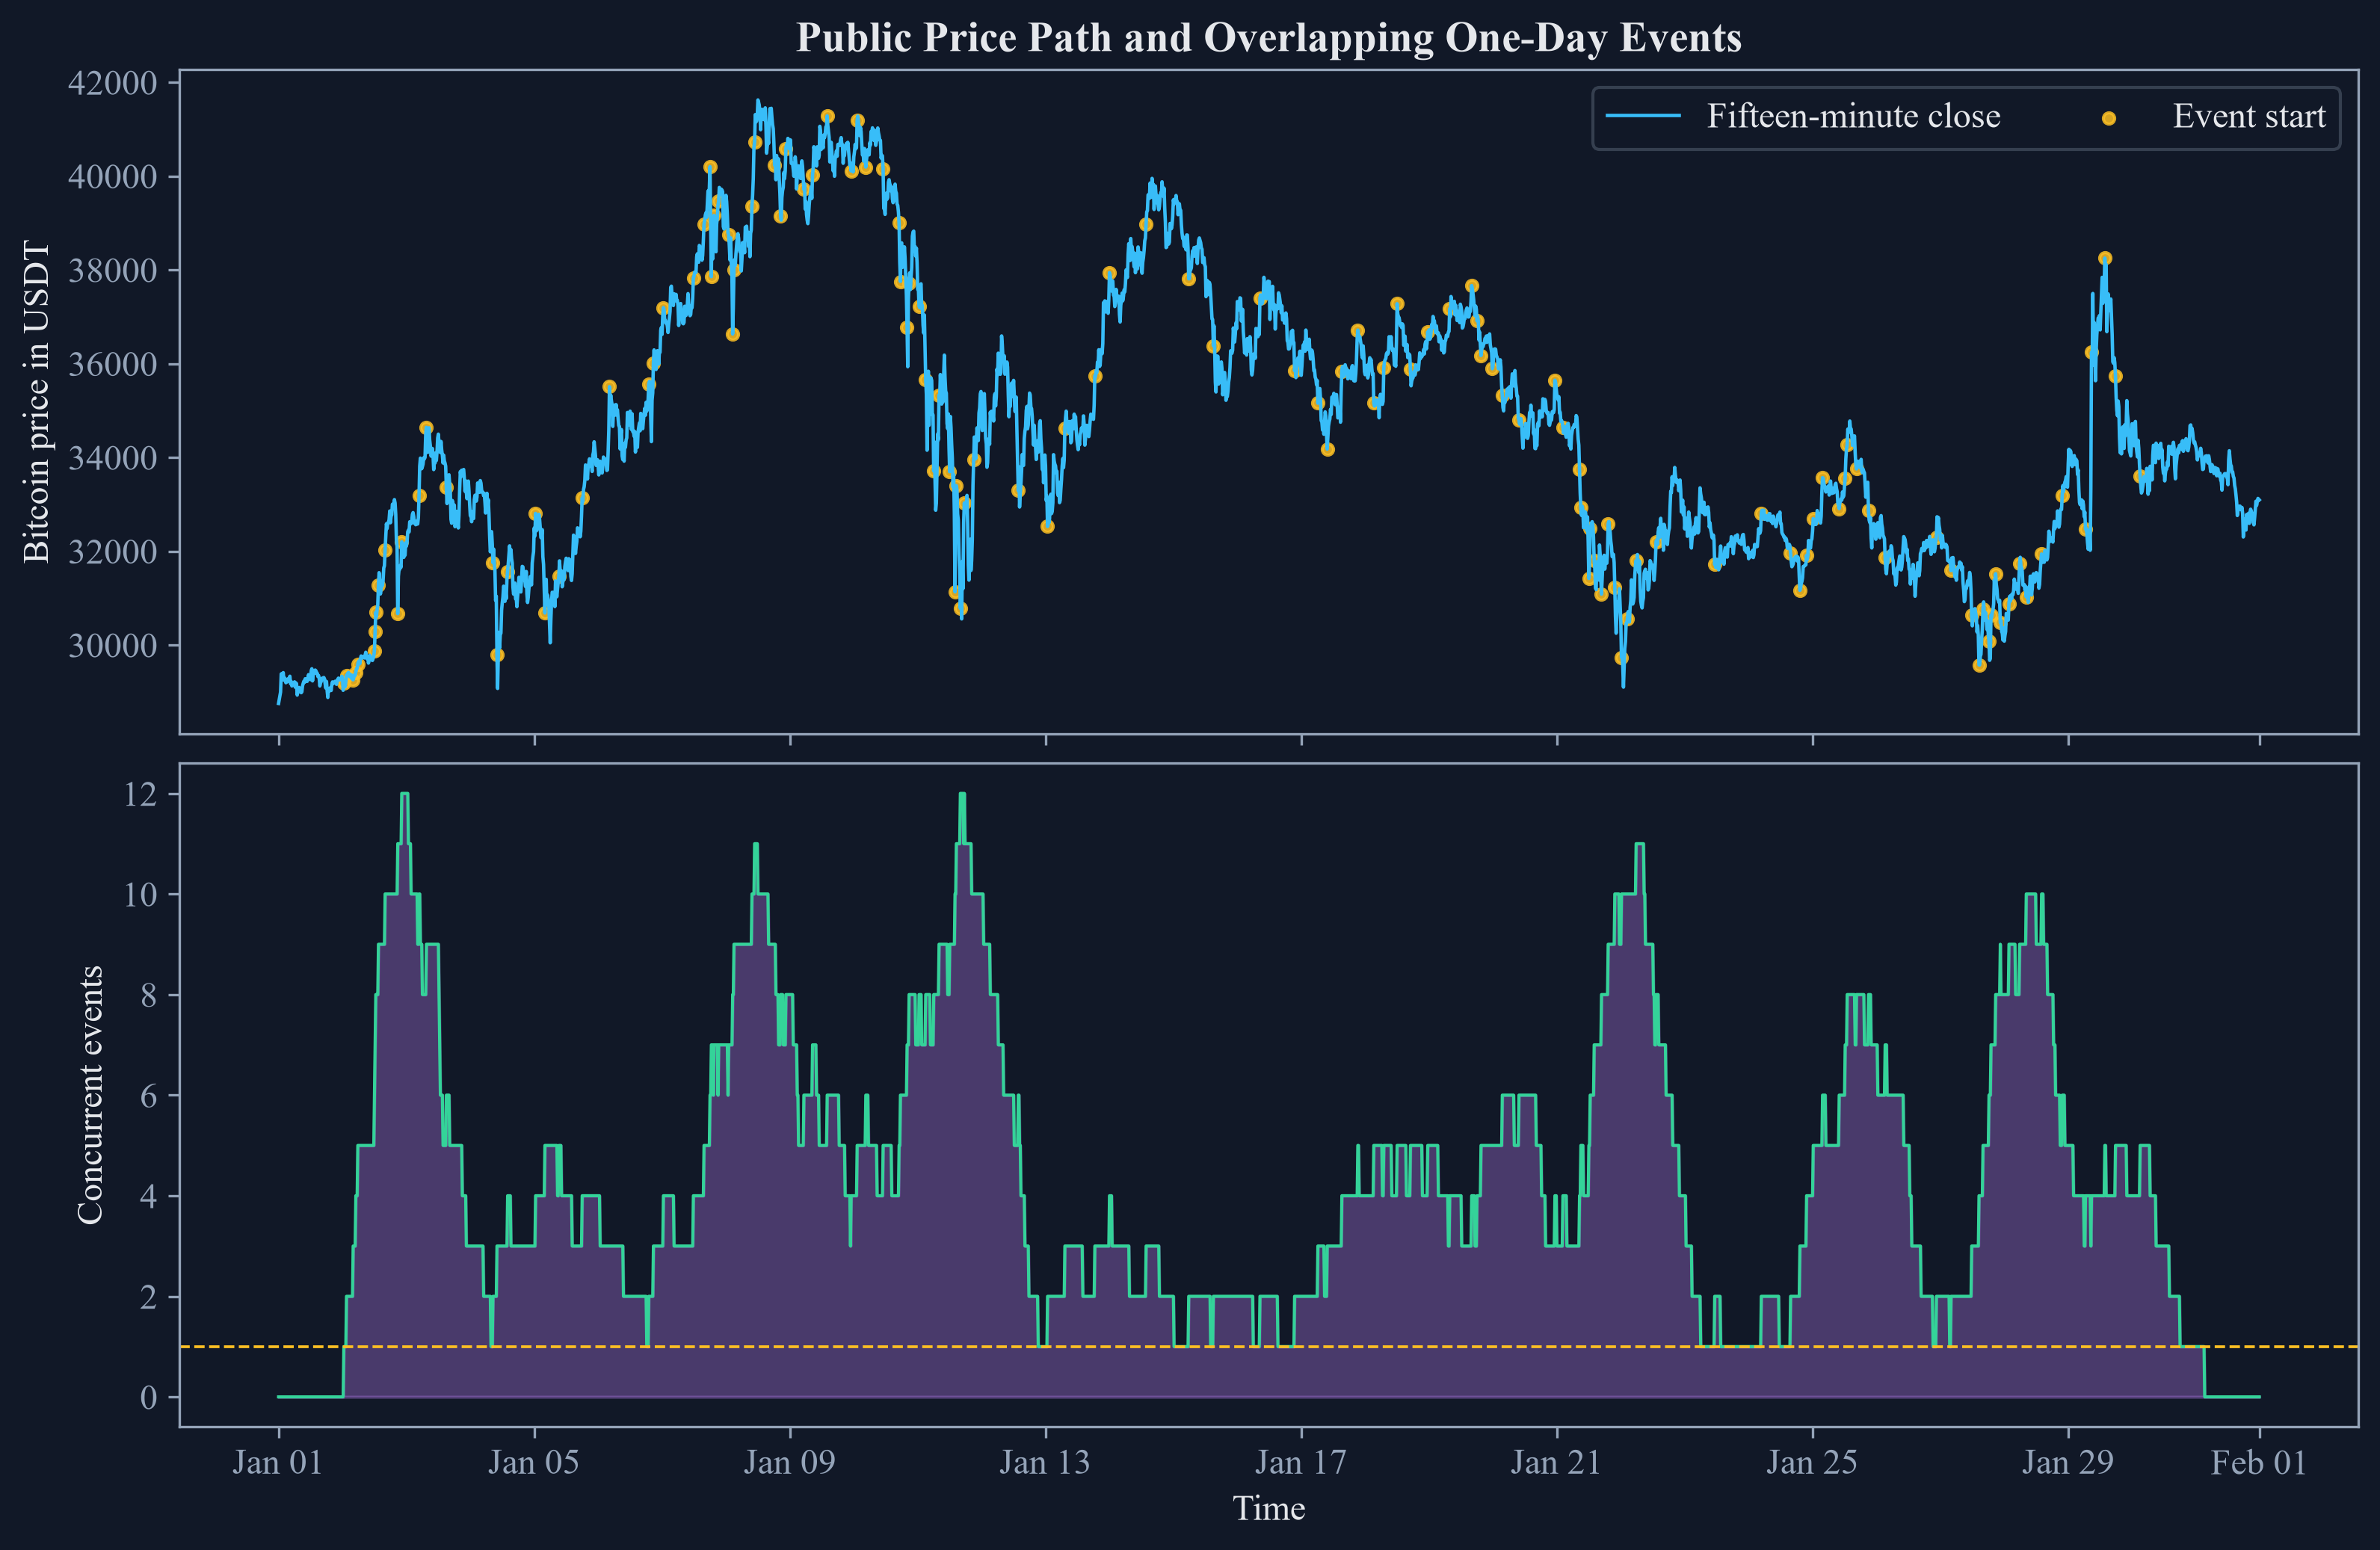

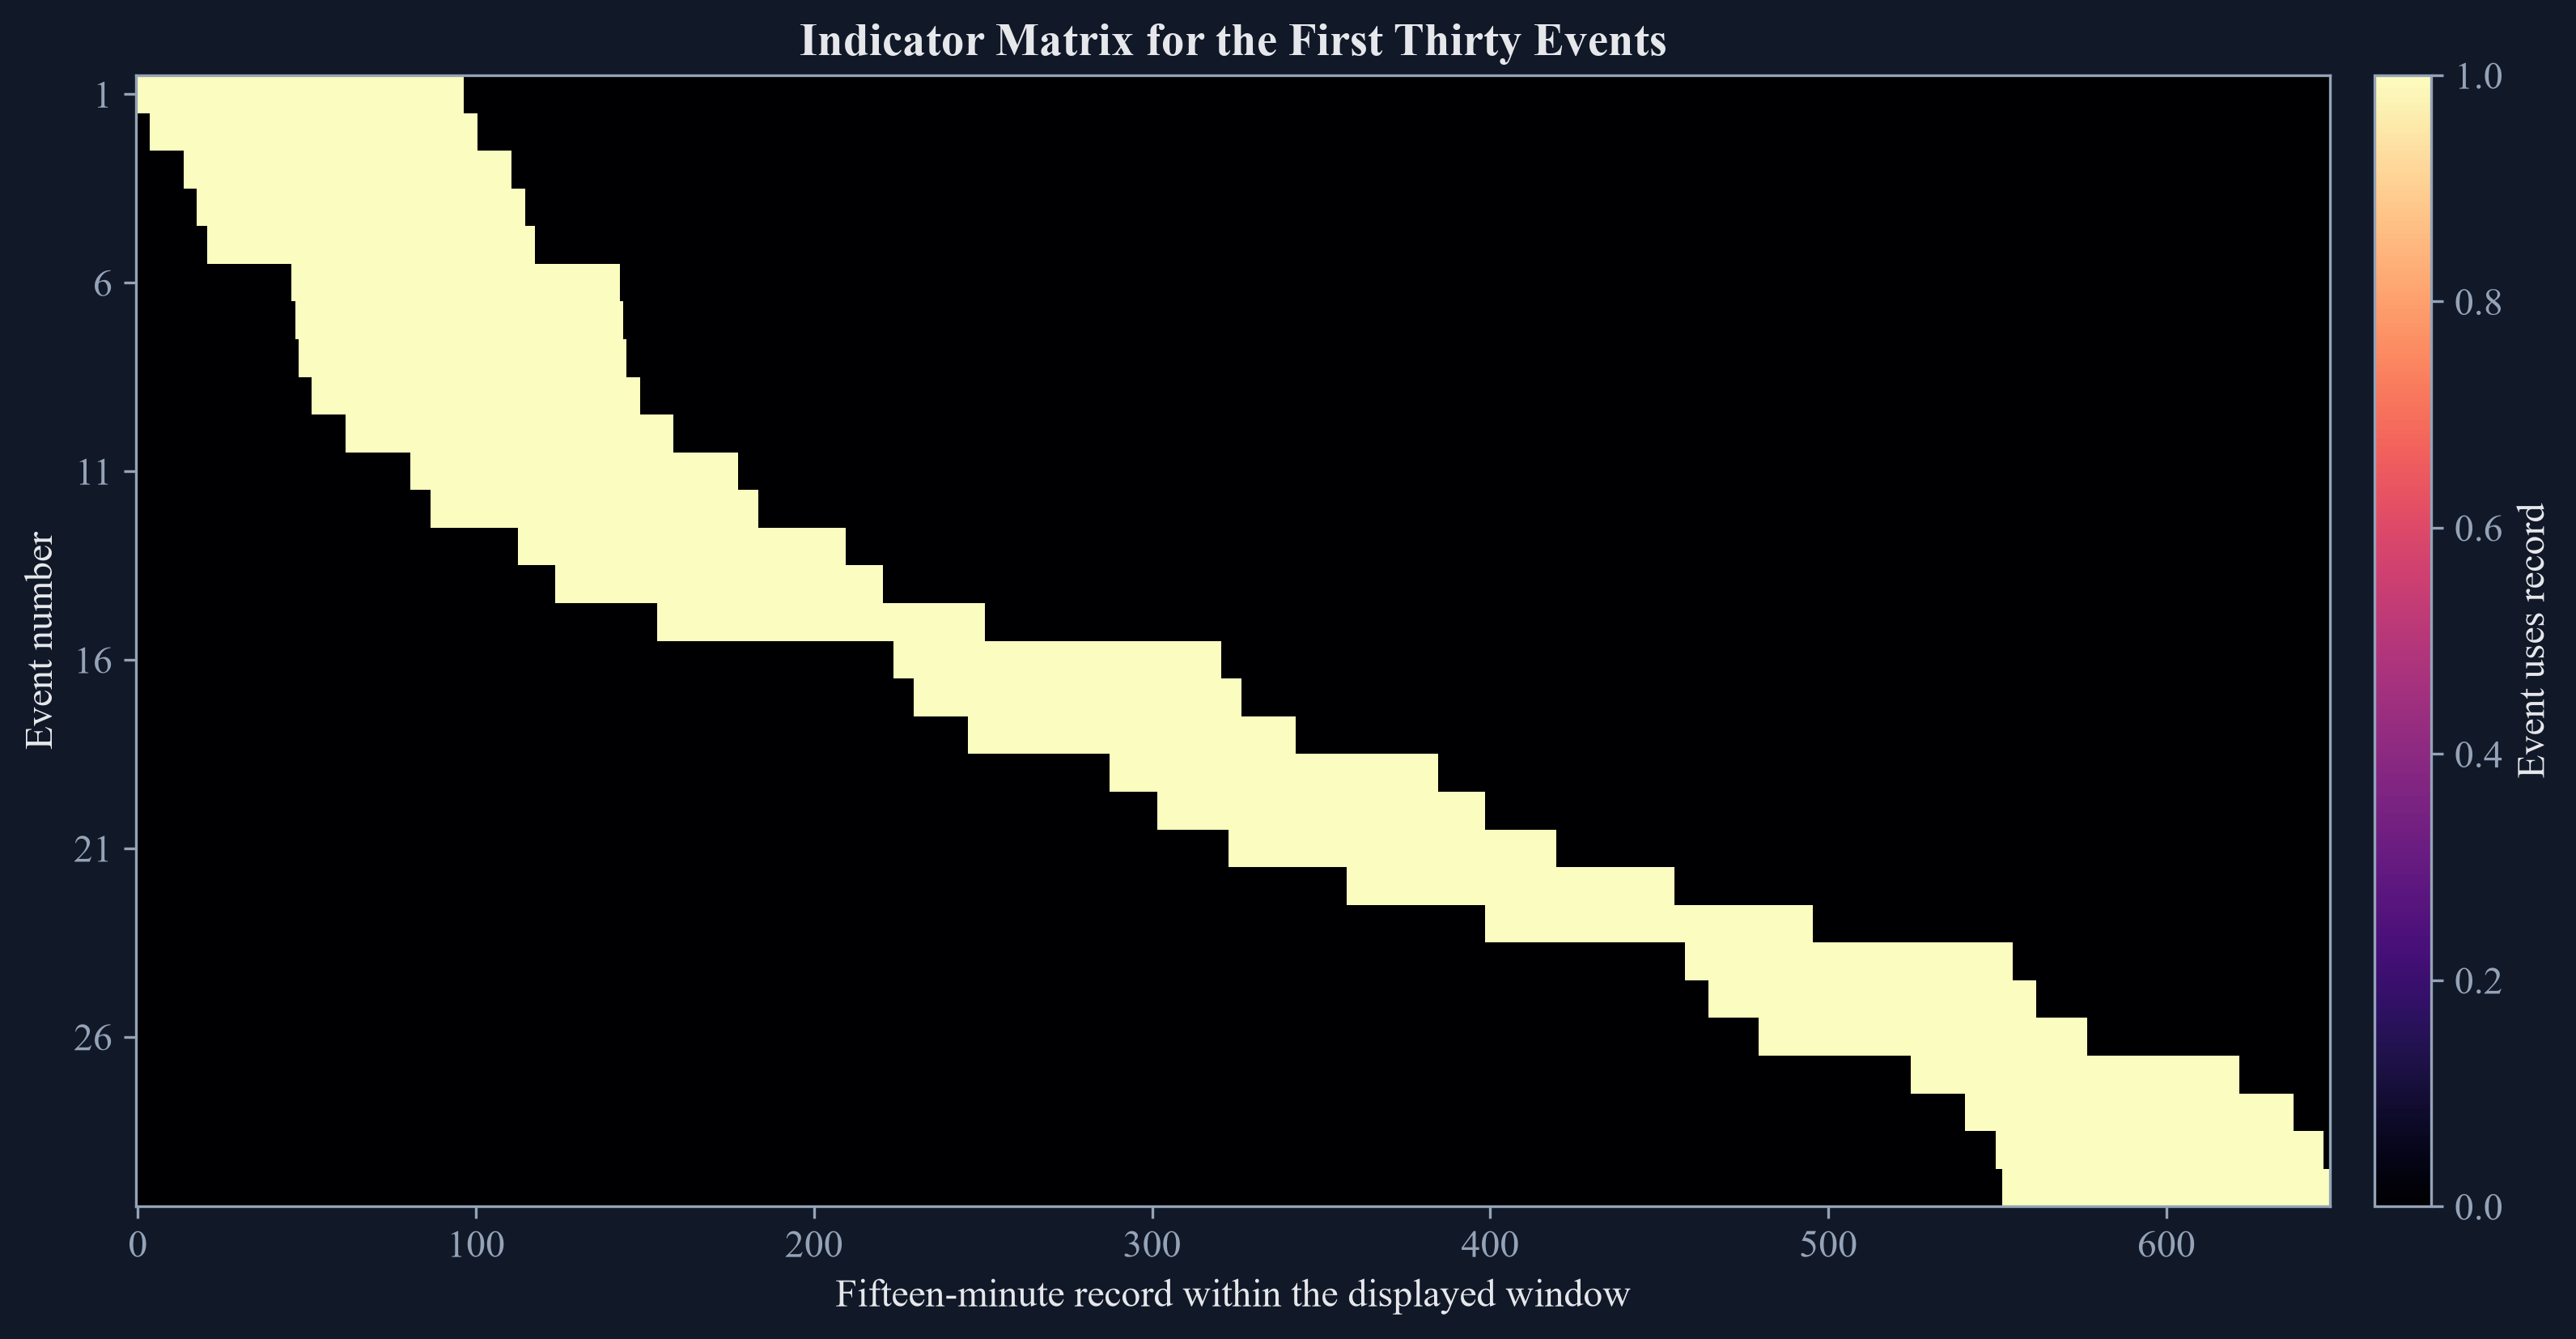

In [3]:
overlap_matrix = indicator_matrix.T.dot(indicator_matrix).astype(int)
figure, axes = plt.subplots(2, 1, figsize=(10.5, 6.8), sharex=True, constrained_layout=True)
axes[0].plot(close.index, close, color=palette["cyan"], linewidth=1.1, label="Fifteen-minute close")
axes[0].scatter(event_times, close.loc[event_times], color=palette["amber"], s=13, alpha=0.85, label="Event start")
axes[0].set_ylabel("Bitcoin price in USDT")
axes[0].set_title("Public Price Path and Overlapping One-Day Events")
axes[0].legend(ncol=2)
axes[1].fill_between(matrix_concurrency.index, matrix_concurrency.to_numpy(), color=palette["violet"], alpha=0.32)
axes[1].plot(matrix_concurrency.index, matrix_concurrency, color=palette["green"], linewidth=1.0)
axes[1].axhline(1, color=palette["amber"], linewidth=0.9, linestyle="--")
axes[1].set_ylabel("Concurrent events")
axes[1].set_xlabel("Time")
axes[1].xaxis.set_major_formatter(mdates.DateFormatter("%b %d"))
figure.savefig(FIGURES / "event_concurrency.png", bbox_inches="tight", dpi=300)
figure.savefig(FIGURES / "event_concurrency.pdf", bbox_inches="tight")
display(Image(filename=str(FIGURES / "event_concurrency.png")))
plt.close(figure)

displayed_events = event_times[:30]
displayed_rows = indicator_matrix.loc[displayed_events.min():event_ends.loc[displayed_events].max(), displayed_events]
figure, axis = plt.subplots(figsize=(10.5, 5.4), constrained_layout=True)
image = axis.imshow(displayed_rows.T.to_numpy(), aspect="auto", interpolation="nearest", cmap="magma")
axis.set_title("Indicator Matrix for the First Thirty Events")
axis.set_xlabel("Fifteen-minute record within the displayed window")
axis.set_ylabel("Event number")
axis.set_yticks(np.arange(0, len(displayed_events), 5))
axis.set_yticklabels(np.arange(1, len(displayed_events) + 1, 5))
colorbar = figure.colorbar(image, ax=axis, pad=0.02)
colorbar.set_label("Event uses record")
figure.savefig(FIGURES / "overlap_indicator.png", bbox_inches="tight", dpi=300)
figure.savefig(FIGURES / "overlap_indicator.pdf", bbox_inches="tight")
display(Image(filename=str(FIGURES / "overlap_indicator.png")))
plt.close(figure)

## Tests

In [4]:
aligned_matrix_concurrency = matrix_concurrency.loc[library_concurrency.index]
assert len(minute_close) == 44640
assert len(close) == 2976
assert len(event_times) == 133
assert event_duration.nunique() == 1
assert event_duration.iloc[0] == 97
assert np.array_equal(library_concurrency.to_numpy(), aligned_matrix_concurrency.to_numpy())
assert int(matrix_concurrency.max()) == 12
assert int((matrix_concurrency > 0).sum()) == 2795
assert float((active_concurrency > 1).mean()) > 0.9
assert np.array_equal(np.diag(overlap_matrix), event_duration.to_numpy())
assert np.all(overlap_matrix.to_numpy() >= 0)
assert np.all(overlap_matrix.to_numpy() <= np.minimum.outer(event_duration.to_numpy(), event_duration.to_numpy()))
assert concurrency_distribution['Fifteen-minute records'].sum() == len(close)
assert np.isclose(concurrency_distribution['Share'].sum(), 1.0)
